# MC Dropout

Los tres dropouts de SEED (antes del BiLSTM, entre sus capas y antes del clasificador) activos al predecir, 30 pasadas con la costura de 20 s / 10 s. Aproxima la incertidumbre epistémica de toda la red. No entrena nada.


**Datos.** Evaluaciones 0, 1 y 2, cinco folds de test cada una (15 folds en total). Se leen los `test_predictions.npz` ya guardados: el notebook no entrena ni vuelve a inferir. Todo se calcula sobre los timesteps válidos.

**Cómo leer las tablas.** Cada tabla muestra *media ± desviación estándar* entre folds para cada evaluación (0, 1 y 2) y el promedio de las tres (los 15 folds juntos). Los gráficos tienen cuatro paneles con las mismas cuatro vistas.

**Definiciones que se repiten**

- *Cerca de eventos*: ±1 s alrededor de un huso real o predicho. Es donde ocurren los errores; el ~92% restante es fondo fácil que infla los AUROC.
- *Azar*: 0.5 para un AUROC; para un AUPRC, la proporción de positivos (tasa de error o proporción de FP/FN).
- *Aleatoria* = entropía esperada (ambigüedad de la señal); *epistémica* = MI (desacuerdo entre muestras del modelo); *total* = entropía predictiva = aleatoria + MI.
- *SEED H(p)*: la incertidumbre del SEED original sobre los mismos timesteps o eventos, como referencia.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

METHOD = 'MC Dropout'
REFRESH = False  # True recalcula desde los NPZ (varios minutos)
results = report.method_results(METHOD, refresh=REFRESH)
metrics = results['metrics']

MC Dropout: evaluación 0 lista
MC Dropout: evaluación 1 lista
MC Dropout: evaluación 2 lista


## 1. Detección y calibración

F1, precisión y recall por evento (IoU ≥ 0.2, métrica principal), AUROC/AUPRC de detección por timestep y calidad de la probabilidad (NLL, Brier y ECE de la clase positiva; menor es mejor).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
F1 evento (%),82.41 ± 0.77,82.93 ± 0.97,82.83 ± 0.99,82.72 ± 0.88
precisión (%),84.52 ± 5.9,85.41 ± 3.1,83.38 ± 3.7,84.44 ± 4.2
recall (%),81.09 ± 6.4,80.75 ± 2.9,82.5 ± 3.2,81.45 ± 4.2
AUROC detección,0.9915 ± 0.00097,0.9916 ± 0.00075,0.9915 ± 0.00032,0.9915 ± 0.00068
AUPRC detección,0.8886 ± 0.0088,0.8901 ± 0.005,0.8868 ± 0.0096,0.8885 ± 0.0076
NLL,0.05097 ± 0.0034,0.04943 ± 0.0026,0.05009 ± 0.0038,0.05016 ± 0.0031
Brier,0.01495 ± 0.00096,0.01465 ± 0.00063,0.01495 ± 0.0012,0.01485 ± 0.0009
ECE clase positiva,0.00645 ± 0.0025,0.003873 ± 0.0021,0.004503 ± 0.0041,0.004942 ± 0.003


F1 evento (%)  precisión (%)  recall (%)  AUROC detección  AUPRC detección     NLL   Brier  ECE clase positiva
evaluación fold                                                                                                                
0          0           82.8518        78.1882     88.1070           0.9915           0.8838  0.0512  0.0151              0.0089
           1           81.6875        84.7931     78.8014           0.9900           0.8770  0.0559  0.0162              0.0047
           2           83.1419        79.7357     86.8522           0.9919           0.8879  0.0495  0.0147              0.0061
           3           82.8978        87.0906     79.0901           0.9913           0.8990  0.0515  0.0152              0.0035
           4           81.4613        92.7950     72.5948           0.9926           0.8953  0.0467  0.0135              0.0090
1          0           83.2165        83.8041     82.6370           0.9922           0.8897  0.0462  0.0139              0.0030
           1           83.7877        86.1357     81.5642           0.9925           0.8975  0.0473  0.0142              0.0031
           2           81.8428        88.9282     75.8032           0.9916           0.8886  0.0501  0.0145              0.0074
           3           81.9672        80.9353     83.0258           0.9908           0.8835  0.0517  0.0154              0.0041
           4           83.8559        87.2444     80.7207           0.9910           0.8910  0.0519  0.0152              0.0018
2          0           82.0305        85.5026     78.8293           0.9911           0.8766  0.0488  0.0146              0.0035
           1           82.0889        77.2064     87.6307           0.9915           0.8974  0.0561  0.0169              0.0118
           2           82.2874        82.7060     81.8731           0.9918           0.8791  0.0469  0.0142              0.0023
           3           83.4791        85.7278     81.3453           0.9913           0.8849  0.0514  0.0152              0.0031
           4           84.2610        85.7422     82.8302           0.9918           0.8961  0.0474  0.0139              0.0017

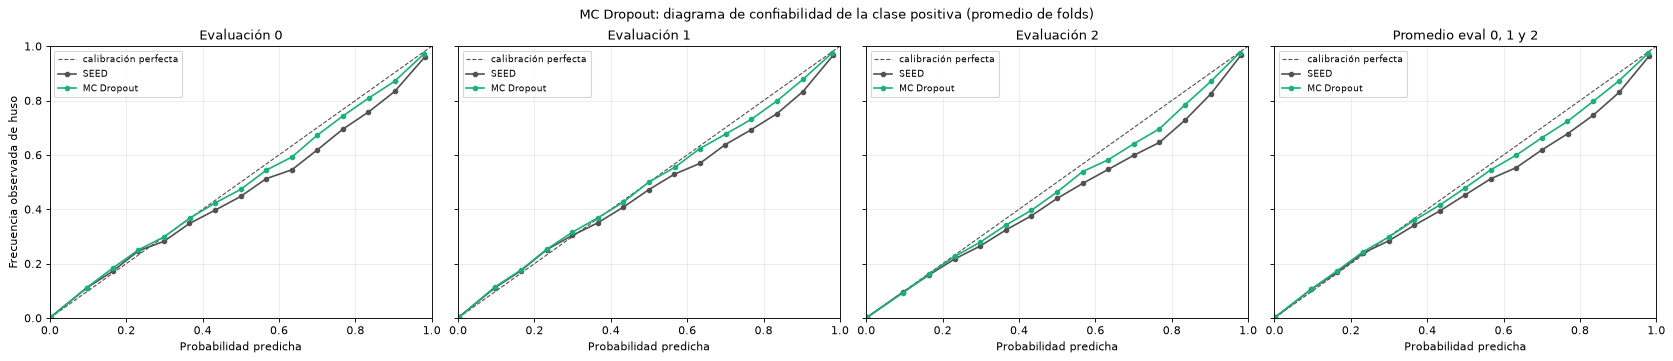

In [2]:
DETECTION = ['F1 evento (%)', 'precisión (%)', 'recall (%)', 'AUROC detección', 'AUPRC detección', 'NLL', 'Brier', 'ECE clase positiva']
display(report.by_evaluation(metrics, DETECTION))
display(metrics.set_index(['evaluación', 'fold'])[DETECTION].round(4))
show(report.plot_reliability(results, METHOD))

## 2. Curvas ROC

Curva promedio de los folds. *Detección*: huso vs fondo con la probabilidad. *Errores*: timesteps mal clasificados vs bien clasificados cerca de eventos, ordenados por cada medida de incertidumbre.

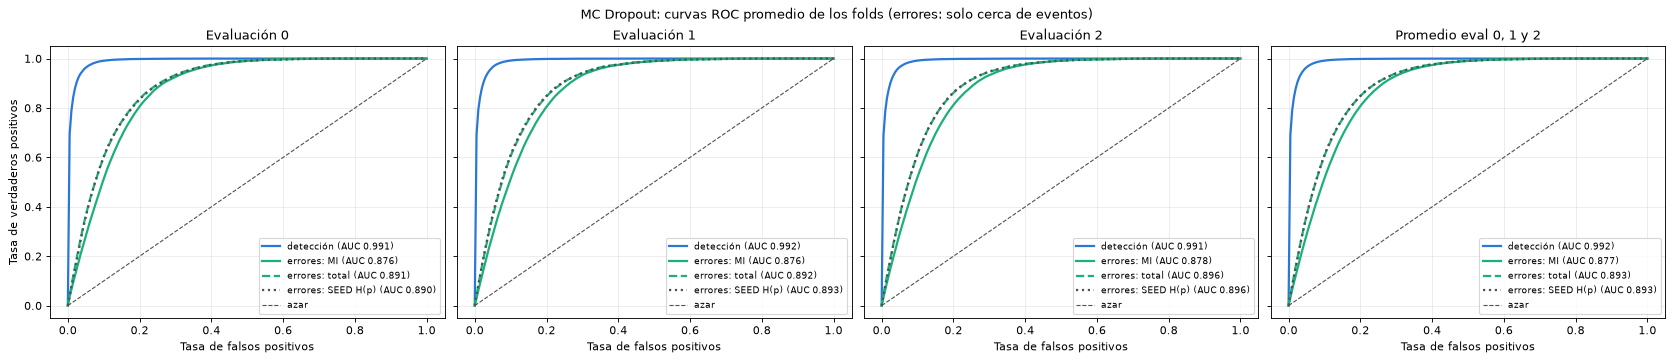

In [3]:
show(report.plot_roc(results, METHOD))

## 3. Descomposición de la incertidumbre

Entropía media en bits, en todo el registro y cerca de eventos, separada en aleatoria y epistémica (MI), con la incertidumbre de SEED como referencia.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
total (registro),0.06488 ± 0.01,0.06324 ± 0.0086,0.06901 ± 0.0067,0.06571 ± 0.0084
aleatoria (registro),0.06361 ± 0.01,0.06198 ± 0.0085,0.06769 ± 0.0066,0.06443 ± 0.0083
SEED H(p) (registro),0.06025 ± 0.0091,0.05881 ± 0.0089,0.06412 ± 0.006,0.06106 ± 0.0079
MI (registro),0.001269 ± 0.0002,0.001269 ± 0.00012,0.001325 ± 0.00018,0.001288 ± 0.00016
% epistémica (registro),1.96 ± 0.19,2.02 ± 0.18,1.92 ± 0.16,1.966 ± 0.17
total (cerca de eventos),0.2417 ± 0.013,0.2417 ± 0.024,0.2497 ± 0.0096,0.2443 ± 0.016
aleatoria (cerca de eventos),0.2367 ± 0.012,0.2367 ± 0.024,0.2447 ± 0.0097,0.2394 ± 0.016
SEED H(p) (cerca de eventos),0.2271 ± 0.01,0.2268 ± 0.026,0.2348 ± 0.0084,0.2296 ± 0.016
MI (cerca de eventos),0.004909 ± 0.00044,0.004983 ± 0.0002,0.00501 ± 0.00026,0.004967 ± 0.0003
% epistémica (cerca de eventos),2.033 ± 0.17,2.078 ± 0.22,2.009 ± 0.14,2.04 ± 0.17


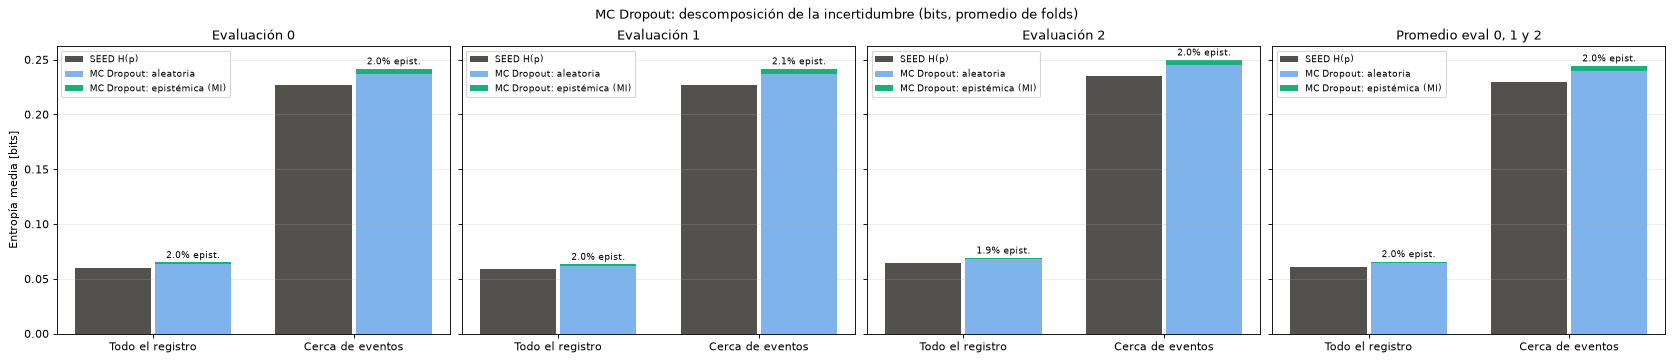

In [4]:
DECOMPOSITION = [c for c in metrics.columns if c.endswith('(registro)') or c.endswith('(cerca de eventos)')]
display(report.by_evaluation(metrics, DECOMPOSITION))
show(report.plot_decomposition(results, METHOD))

## 4. ¿La incertidumbre detecta los errores?

Errores por timestep cerca de eventos: AUROC y AUPRC de cada medida. El AUPRC se compara con la tasa de error (azar).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
AUROC errores: total,0.8905 ± 0.006,0.8924 ± 0.0082,0.8956 ± 0.0029,0.8929 ± 0.006
AUPRC errores: total,0.4106 ± 0.0071,0.4107 ± 0.0097,0.4183 ± 0.0064,0.4132 ± 0.0082
AUROC errores: aleatoria,0.8905 ± 0.0058,0.8924 ± 0.0081,0.8956 ± 0.0026,0.8928 ± 0.0059
AUPRC errores: aleatoria,0.4095 ± 0.0073,0.4091 ± 0.011,0.417 ± 0.0074,0.4119 ± 0.0088
AUROC errores: SEED H(p),0.8896 ± 0.003,0.8934 ± 0.0068,0.8956 ± 0.0022,0.8929 ± 0.0049
AUPRC errores: SEED H(p),0.4061 ± 0.021,0.4148 ± 0.019,0.4144 ± 0.023,0.4118 ± 0.02
AUROC errores: MI,0.8757 ± 0.011,0.8762 ± 0.016,0.8782 ± 0.014,0.8767 ± 0.013
AUPRC errores: MI,0.3642 ± 0.023,0.3599 ± 0.029,0.367 ± 0.04,0.3637 ± 0.029
azar errores,0.1047 ± 0.0039,0.1037 ± 0.0054,0.1043 ± 0.005,0.1043 ± 0.0045


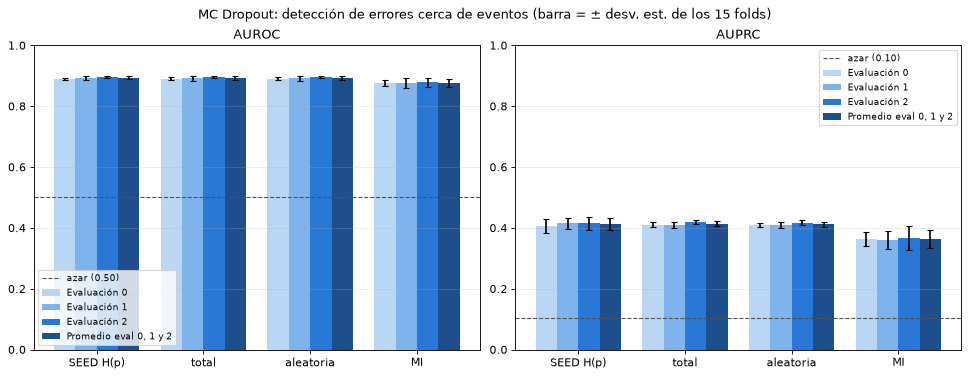

In [5]:
ERRORS = [c for c in metrics.columns if c.startswith('AUROC errores') or c.startswith('AUPRC errores')] + ['azar errores']
display(report.by_evaluation(metrics, ERRORS))
show(report.plot_error_detection(results, METHOD))

## 5. Dónde se concentra la incertidumbre

Entropía media por zona: bordes de los husos (±0.25 s del inicio o fin real), interior del huso y fondo.

Borde del huso
Interior del huso
Fondo


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,6.124 ± 0.34,6.124 ± 0.24,6.124 ± 0.36,6.124 ± 0.3
SEED H(p),0.4373 ± 0.015,0.4373 ± 0.033,0.4466 ± 0.014,0.4404 ± 0.021
aleatoria,0.4544 ± 0.017,0.4543 ± 0.029,0.4634 ± 0.015,0.4574 ± 0.02
MI,0.009601 ± 0.00077,0.009663 ± 0.00053,0.009591 ± 0.00051,0.009618 ± 0.00057


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,2.055 ± 0.25,2.055 ± 0.19,2.055 ± 0.2,2.055 ± 0.2
SEED H(p),0.2824 ± 0.076,0.2848 ± 0.057,0.2954 ± 0.066,0.2876 ± 0.062
aleatoria,0.3108 ± 0.073,0.3127 ± 0.052,0.3249 ± 0.071,0.3162 ± 0.061
MI,0.006683 ± 0.00086,0.006882 ± 0.00062,0.006984 ± 0.00082,0.00685 ± 0.00073


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,91.82 ± 0.53,91.82 ± 0.36,91.82 ± 0.55,91.82 ± 0.45
SEED H(p),0.03029 ± 0.011,0.02841 ± 0.0057,0.0336 ± 0.006,0.03076 ± 0.0077
aleatoria,0.03217 ± 0.012,0.0301 ± 0.0056,0.03571 ± 0.0065,0.03266 ± 0.0081
MI,0.0005933 ± 0.00017,0.0005829 ± 0.00012,0.0006492 ± 0.00016,0.0006085 ± 0.00014


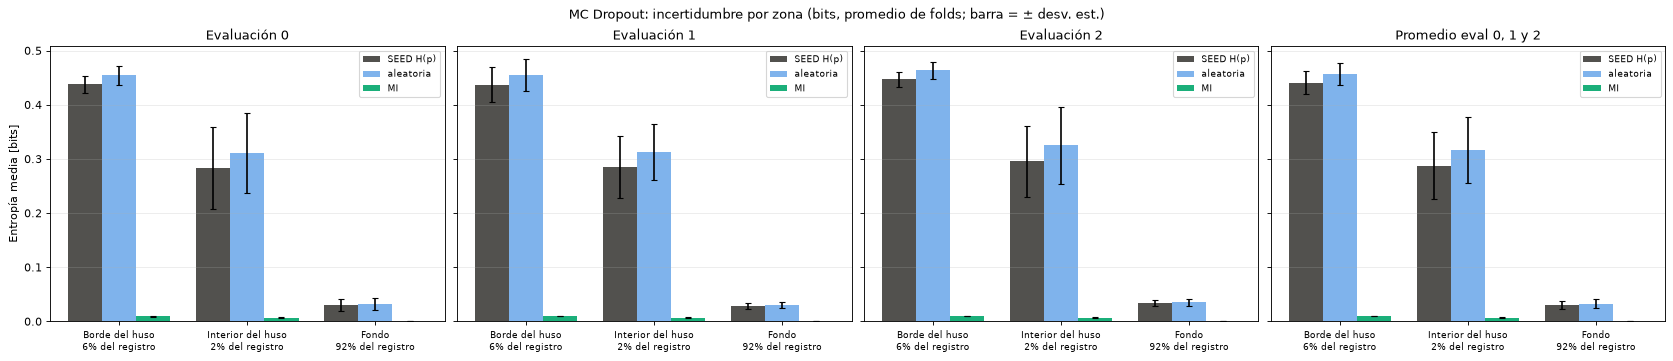

In [6]:
zones = results['zones']
for zone in ['Borde del huso', 'Interior del huso', 'Fondo']:
    print(zone)
    display(report.by_evaluation(zones[zones['zona'] == zone], [c for c in zones.columns if c not in ('evaluación', 'fold', 'zona')]))
show(report.plot_zones(results, METHOD))

## 6. Duración del evento vs incertidumbre

ρ es la correlación de Spearman entre la duración de cada evento predicho y su incertidumbre media (MI; para SEED, su entropía). ρ < 0: los eventos cortos son más inciertos.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
ρ duración-incertidumbre,-0.7074 ± 0.043,-0.7006 ± 0.053,-0.6764 ± 0.041,-0.6948 ± 0.045


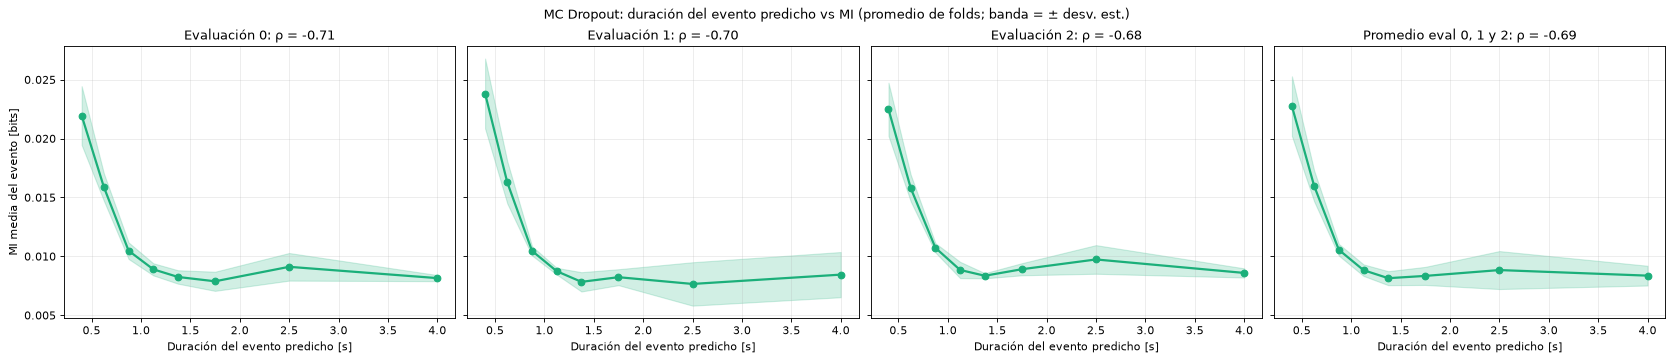

In [7]:
display(report.by_evaluation(metrics, ['ρ duración-incertidumbre']))
show(report.plot_duration(results, METHOD))

## 7. Aciertos, falsos positivos y falsos negativos

- **TP / FP (predicho)**: detecciones correctas y falsas, medidas en el tramo que el modelo predijo.
- **TP / FN (real)**: husos detectados y no detectados, medidos en el tramo real del huso (un FN no tiene tramo predicho). Los pares con IoU < 0.2 cuentan como FN, igual que en el F1.

Primero las medianas de cada medida, luego qué tan bien cada medida separa FP de TP y FN de TP (AUROC y AUPRC con su azar), y al final los gráficos de cajón en percentil dentro del fold, con la línea de azar en 0.5. Comparar la *probabilidad media* entre FN y TP es casi circular (un FN es justamente un tramo con probabilidad baja).

Medianas por tipo de evento
FP vs TP (tramo predicho)
FN vs TP (tramo real)


eval 0                                                                                           eval 1                                                                                           eval 2                      \
              probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total   
grupo                                                                                                                                                                                                                                                    
TP (predicho)             0.8589              0.4715    0.4598          0.0109                          0.0385             0.8601              0.4711    0.4597          0.0106                          0.0378             0.8613              0.4710   
FP (predicho)             0.6110              0.9476    0.9266          0.0197                          0.0779             0.6235              0.9338    0.9111          0.0202                          0.0776             0.6348              0.9239   
TP (real)                 0.8454              0.4426    0.4322          0.0101                          0.0352             0.8447              0.4409    0.4305          0.0098                          0.0352             0.8449              0.4430   
FN (real)                 0.1809              0.6301    0.6188          0.0103                          0.0443             0.1893              0.6535    0.6423          0.0108                          0.0461             0.1969              0.6437   

                                                                        promedio eval 0, 1 y 2                                                                                
              aleatoria epistémica (MI) dispersión entre muestras (std)     probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std)  
grupo                                                                                                                                                                         
TP (predicho)    0.4601          0.0108                          0.0381                 0.8602              0.4713    0.4598          0.0108                          0.0382  
FP (predicho)    0.9003          0.0197                          0.0769                 0.6229              0.9353    0.9115          0.0199                          0.0774  
TP (real)        0.4332          0.0099                          0.0351                 0.8451              0.4424    0.4322          0.0099                          0.0351  
FN (real)        0.6339          0.0103                          0.0440                 0.1891              0.6409    0.6301          0.0105                          0.0449

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1548 ± 0.059,0.1459 ± 0.031,0.1662 ± 0.037,0.1556 ± 0.042
AUROC probabilidad media,0.8558 ± 0.013,0.8456 ± 0.012,0.8443 ± 0.03,0.8485 ± 0.019
AUPRC probabilidad media,0.4565 ± 0.11,0.4445 ± 0.08,0.4692 ± 0.11,0.4567 ± 0.094
AUROC incertidumbre total,0.8577 ± 0.011,0.8494 ± 0.013,0.8493 ± 0.028,0.8521 ± 0.018
AUPRC incertidumbre total,0.455 ± 0.14,0.4384 ± 0.087,0.469 ± 0.11,0.4541 ± 0.11
AUROC aleatoria,0.8579 ± 0.011,0.8486 ± 0.013,0.8491 ± 0.028,0.8518 ± 0.018
AUPRC aleatoria,0.4535 ± 0.13,0.4249 ± 0.084,0.4523 ± 0.11,0.4435 ± 0.1
AUROC epistémica (MI),0.8166 ± 0.016,0.8198 ± 0.011,0.8142 ± 0.04,0.8169 ± 0.024
AUPRC epistémica (MI),0.3796 ± 0.13,0.3598 ± 0.07,0.3844 ± 0.13,0.3746 ± 0.11
AUROC dispersión entre muestras (std),0.8448 ± 0.0075,0.8395 ± 0.01,0.8364 ± 0.032,0.8402 ± 0.019


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1889 ± 0.064,0.1925 ± 0.029,0.175 ± 0.032,0.1855 ± 0.042
AUROC probabilidad media,0.963 ± 0.015,0.9673 ± 0.014,0.9564 ± 0.03,0.9622 ± 0.02
AUPRC probabilidad media,0.9418 ± 0.03,0.9508 ± 0.017,0.931 ± 0.047,0.9412 ± 0.032
AUROC incertidumbre total,0.5907 ± 0.094,0.608 ± 0.052,0.6136 ± 0.048,0.6041 ± 0.064
AUPRC incertidumbre total,0.2315 ± 0.04,0.2522 ± 0.033,0.2257 ± 0.017,0.2365 ± 0.031
AUROC aleatoria,0.593 ± 0.095,0.6103 ± 0.051,0.6164 ± 0.048,0.6066 ± 0.064
AUPRC aleatoria,0.2334 ± 0.04,0.2552 ± 0.033,0.2281 ± 0.017,0.2389 ± 0.031
AUROC epistémica (MI),0.4746 ± 0.076,0.5049 ± 0.1,0.4863 ± 0.085,0.4886 ± 0.083
AUPRC epistémica (MI),0.1825 ± 0.047,0.2041 ± 0.04,0.173 ± 0.015,0.1865 ± 0.036
AUROC dispersión entre muestras (std),0.5313 ± 0.084,0.5535 ± 0.078,0.548 ± 0.063,0.5443 ± 0.071


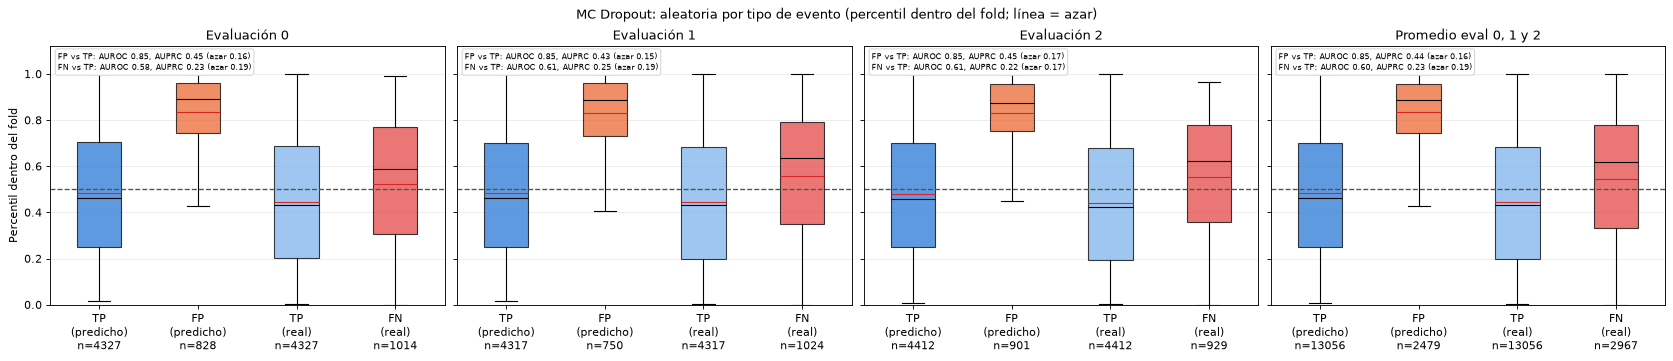

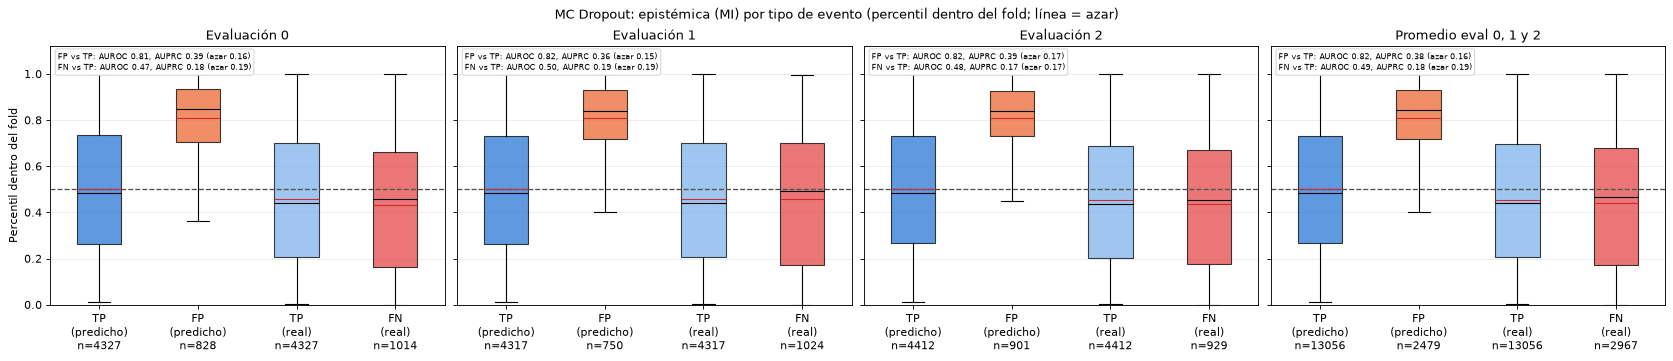

In [8]:
events = results['events']
print('Medianas por tipo de evento')
display(report.event_medians(events))
print('FP vs TP (tramo predicho)')
display(report.event_separation(events, 'TP (predicho)', 'FP (predicho)'))
print('FN vs TP (tramo real)')
display(report.event_separation(events, 'TP (real)', 'FN (real)'))
for figure in report.plot_event_boxes(results, METHOD):
    show(figure)

## 8. Derivar a revisión las detecciones más inciertas

Si se manda a revisión el x% de detecciones con más incertidumbre, ¿qué precisión tiene lo que se acepta automáticamente y qué parte de los falsos positivos se captura?

eval 0
eval 1
eval 2
promedio eval 0, 1 y 2


precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.5            84.5                84.5                0.0             0.0                 0.0
5.0                          86.4            86.0                86.4               17.6            13.7                16.4
10.0                         88.3            87.4                88.4               32.3            27.4                33.1
20.0                         91.9            90.4                92.1               59.5            51.7                60.1
30.0                         94.6            92.7                94.6               77.2            67.4                77.7

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          85.4            85.4                85.4                0.0             0.0                 0.0
5.0                          87.2            86.7                87.3               16.4            13.6                17.6
10.0                         89.1            88.2                89.1               32.9            27.2                32.9
20.0                         92.3            90.9                92.5               57.8            50.1                58.8
30.0                         94.7            93.8                94.8               74.7            70.6                75.2

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          83.4            83.4                83.4                0.0             0.0                 0.0
5.0                          85.3            84.8                85.2               16.1            12.5                15.4
10.0                         87.1            86.2                87.2               30.1            24.7                30.4
20.0                         90.6            89.0                90.7               54.7            46.6                55.0
30.0                         94.1            92.6                94.1               75.1            68.0                74.8

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.4            84.4                84.4                0.0             0.0                 0.0
5.0                          86.3            85.8                86.3               16.7            13.3                16.5
10.0                         88.2            87.3                88.2               31.8            26.4                32.1
20.0                         91.6            90.1                91.7               57.3            49.5                58.0
30.0                         94.5            93.0                94.5               75.7            68.7                75.9

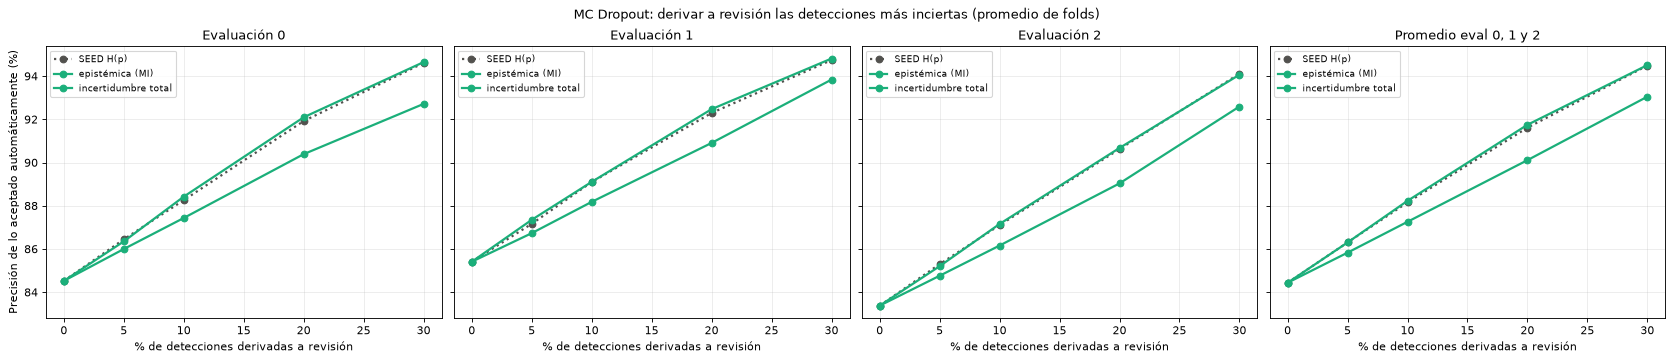

In [9]:
deferral = results['deferral'].dropna(subset=['% derivado'])
for label, part in [(f'eval {e}', deferral[deferral['evaluación'] == e]) for e in report.EVALUATIONS] + [(report.MEAN_SCOPE.lower(), deferral)]:
    print(label)
    display(part.groupby(['medida', '% derivado'])[['precisión aceptado (%)', '% de FP capturados']].mean().round(1).unstack('medida'))
show(report.plot_deferral(results, METHOD))

## 9. Descartar automáticamente las detecciones más inciertas

Sin revisión humana: se eliminan las detecciones con mayor incertidumbre (MI; para SEED, entropía). Los aciertos eliminados pasan a ser falsos negativos. Para que el F1 suba, más de ~58% de lo descartado debe ser FP (con F1 ≈ 83%, el equilibrio es 1 − F1/2).

FP descartados  TP descartados  % FP en lo descartado  cambio F1 (puntos)
medida              % descartado                                                                           
SEED H(p)           0.5                     2.67            2.53                  49.76               -0.04
                    1.0                     5.60            4.60                  53.67               -0.04
                    2.0                    11.47            9.27                  54.12               -0.08
                    5.0                    26.93           24.80                  51.04               -0.35
                    10.0                   51.93           51.60                  49.01               -0.93
                    20.0                   94.00          113.13                  44.27               -3.01
epistémica (MI)     0.5                     1.73            3.47                  31.92               -0.13
                    1.0                     4.33            5.87                  40.98               -0.16
                    2.0                     8.80           11.93                  41.05               -0.34
                    5.0                    22.53           29.20                  42.04               -0.80
                    10.0                   43.60           59.93                  40.95               -1.77
                    20.0                   81.40          125.73                  38.25               -4.33
incertidumbre total 0.5                     3.33            1.87                  62.05                0.02
                    1.0                     6.00            4.20                  57.30               -0.01
                    2.0                    11.60            9.13                  54.83               -0.06
                    5.0                    27.00           24.73                  51.00               -0.35
                    10.0                   52.73           50.80                  49.69               -0.86
                    20.0                   95.13          112.00                  44.80               -2.89

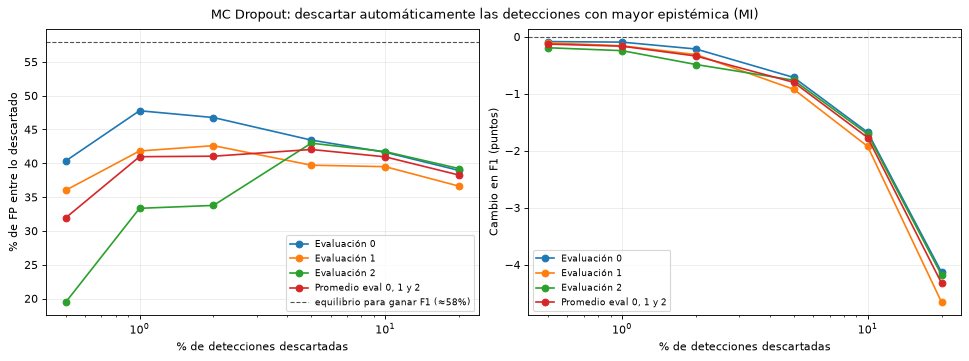

In [10]:
rejection = results['deferral'].dropna(subset=['% descartado'])
display(rejection.groupby(['medida', '% descartado'])[['FP descartados', 'TP descartados', '% FP en lo descartado', 'cambio F1 (puntos)']].mean().round(2))
show(report.plot_rejection(results, METHOD))

## Hallazgos

Cifras como eval 0 / eval 1 / eval 2 / promedio de las tres (15 folds de test); un solo número es el promedio.

1. **La detección no cambia y la calibración mejora levemente:** F1 82.4% / 82.9% / 82.8% / 82.7%, ECE 0.007 / 0.004 / 0.005 / 0.005 (SEED 0.006) y NLL 0.050 (SEED 0.051).
2. **La parte epistémica es pequeña** (2.0% / 2.1% / 2.0% / 2.0%) y se concentra en los bordes de los husos.
3. **Su MI es mucho más útil que la de Laplace:** AUROC de errores 0.876 / 0.876 / 0.878 / 0.877 y AUPRC 0.36 (azar 0.10). Perturbar toda la red, incluido el BiLSTM, captura incertidumbre que la última capa no ve.
4. **Falsos positivos:** la MI los separa con AUROC 0.82 y AUPRC 0.38 (azar 0.16). **Falsos negativos:** queda en el azar (AUROC 0.49).
5. **Los eventos cortos son los más inciertos** (ρ = −0.69, la correlación más fuerte de todos los métodos).
6. **Descartar por MI no mejora el F1** (~40% de FP entre lo descartado); derivar a revisión el 20% más incierto sube la precisión de lo aceptado de 84.4% a 91.7%.

**Conclusión.** Es la mejor opción sin reentrenar: MI útil para falsos positivos y calibración algo mejor, sin costo de entrenamiento. No detecta los husos perdidos.